In [2]:
import numpy as np
import scipy.stats

import matplotlib.pyplot as plt

In [3]:
title = "# Sampling 2: Exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Sampling 2: Exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

We use the two targets from last week: the 1D Gamma distribution from the lecture and the 2D Gaussian from the Metropolis-Hastings exercise.

In [4]:
# 1D target from the lecture
target_distr_1d = scipy.stats.gamma(a=3, scale=1/3)

# 2D Gaussian from the Metropolis-Hastings exercise
sigma_x = 1
sigma_y = 2
rho = 0.7

mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Exact samples, to compare your samplers against
np.random.seed(42)
true_samples = bivariate_normal.rvs(size=10_000)

### Exercise 1: Slice sampling

- Implement your own slice sampler and sample from the 1D Gamma distribution. Compare a histogram of the samples to the PDF.
- How does the step size $w$ change the result? Try $w = 0.01, 1, 100$.
- Extend your sampler to 2D by updating one coordinate at a time, and sample from the 2D Gaussian.

### Exercise 2: Burn-in and auto-correlation

- Run your Metropolis-Hastings and slice samplers on the 2D Gaussian, starting far from the mean, e.g. at $(10, -10)$.
- Plot the chains. How long is the burn-in?
- After removing the burn-in, compute the auto-correlation time of each chain with `emcee.autocorr.integrated_time`. Which sampler gives more independent samples?

### Exercise 3: Nested sampling

- Implement your own nested sampling routine for $n$ dimensions. Use rejection sampling from the prior to find new live points, as in the lecture.
- Compute the evidence $Z$ for the 2D Gaussian likelihood with a uniform prior on $[-7, 7]^2$. Show that the exact answer is $Z \approx 1/14^2$ and compare.
- How many tries does it take to find each new live point? Why does this number grow during the run?
- Weight the dead points to get posterior samples and compare them to `true_samples`.

### Exercise 4: emcee and dynesty

- Sample the 2D Gaussian with `emcee` and with `dynesty` (same uniform prior on $[-7, 7]^2$).
- Compare the samples to `true_samples` and to your own samplers in a corner plot.
- Compare $\ln Z$ from `dynesty` to the exact value and to your own nested sampler.

### Exercise 5: Model comparison

Go back to the line-fitting exercise and take the data in `lectures/data/linear_fits/data_2.txt`. Compare two models:
\begin{align}
    M_1:&\quad \mu(x) = mx + b \\
    M_2:&\quad \mu(x) = ax^2 + bx + c
\end{align}
Use the Gaussian likelihood $y_i\sim\Norm(\mu(x_i), \sigma_{y_i}^2)$ and uniform priors $\Uniform(-3, 3)$ on all parameters.

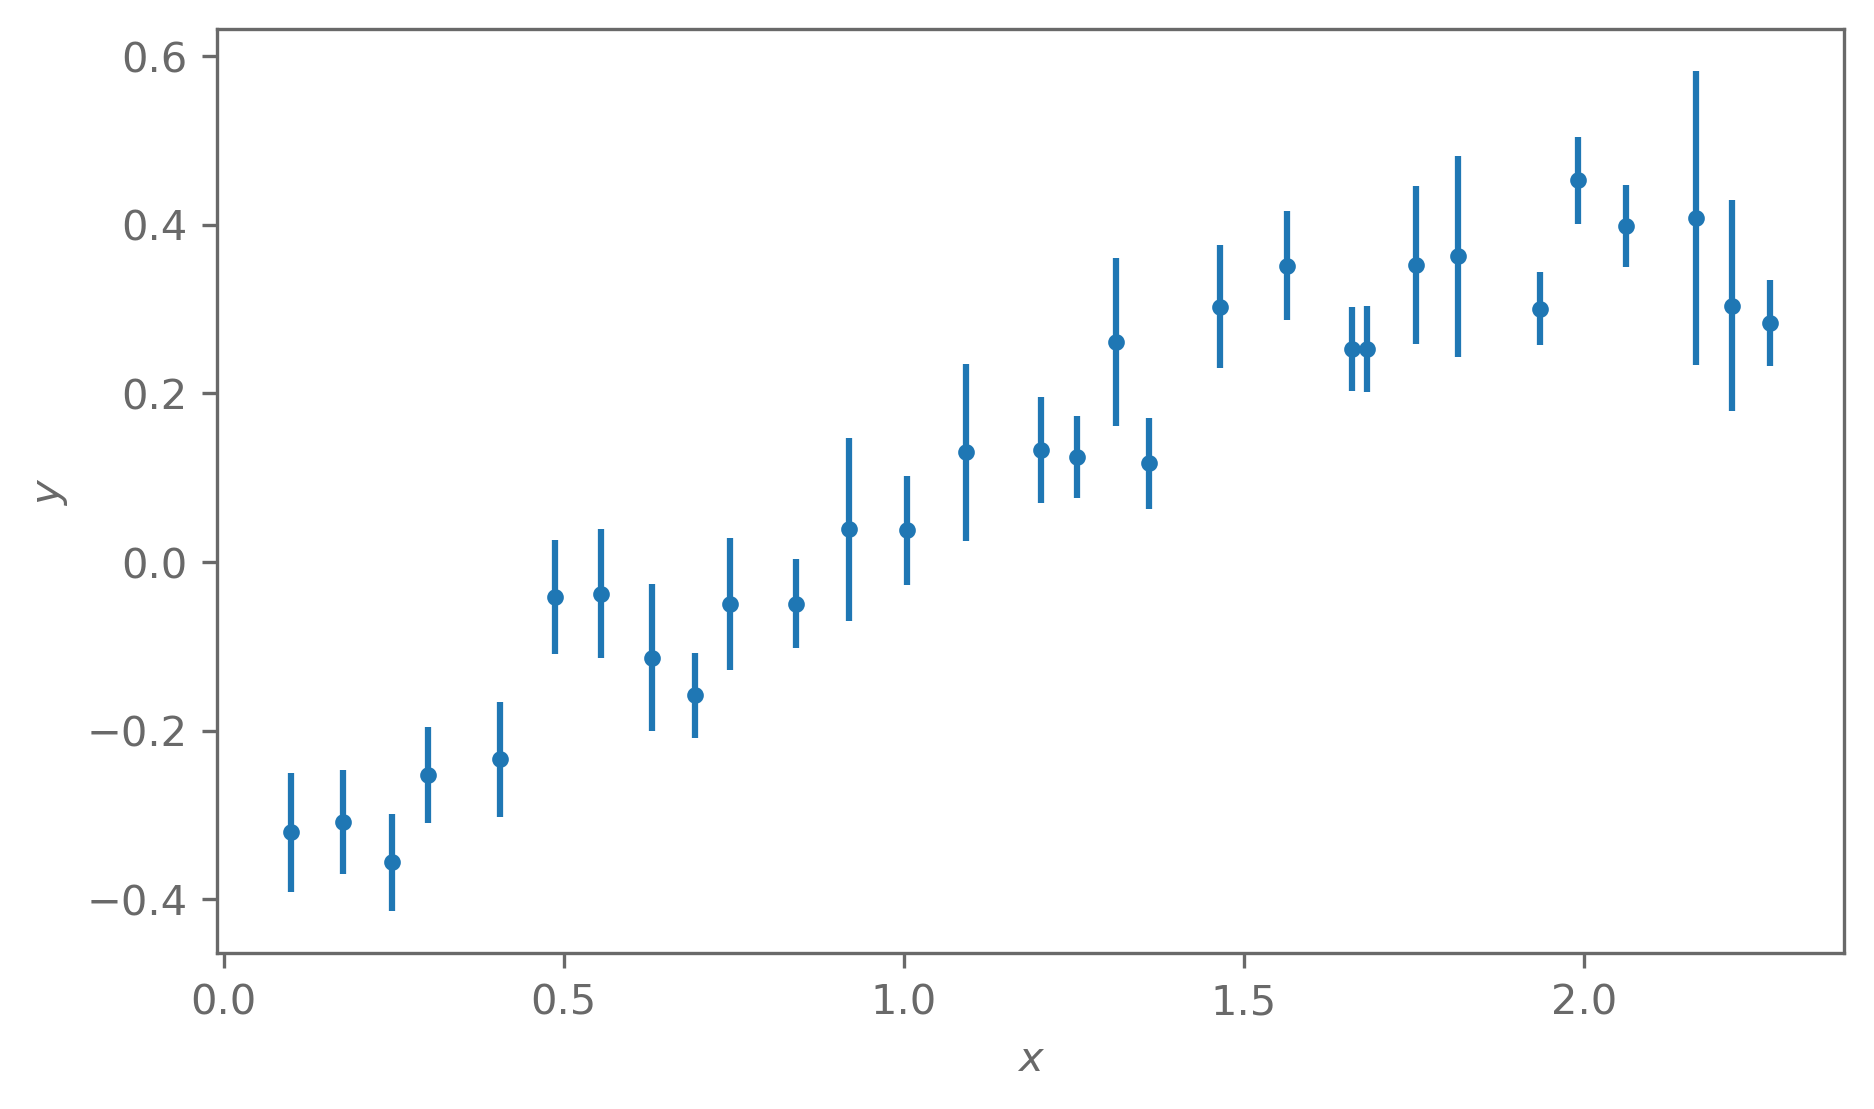

In [5]:
x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_2.txt", unpack=True)

plt.errorbar(x, y, y_err, fmt=".")
plt.xlabel("$x$")
plt.ylabel("$y$");

- Use `dynesty` to compute the evidence of each model. Which model is preferred by the data, and how strongly?
- Repeat with `data_0.txt`. Which model is preferred now?
- Widen the prior on $a$ to $\Uniform(-30, 30)$. How do the posterior and the Bayes' ratio change?